# Лабораторная работа 1: Предварительный статистический анализ данных Фишера.

### Общее задание:
Для данных Фишера (файл irisdat):
1. Проверить предположение о том, что математической моделью данных является модель «случайная выборка».
2. Исследовать закон распределения случайных выборок, соответствующих переменным var1–var4.
3. Проверить предположение о нормальном распределении выборок.
4. Исследовать однородность данных по среднему значению и дисперсии значений переменных var1–var4, относящихся к различным типам ирисов, видам 1, 2, 3 (var5).
5. С помощью графического анализа и тестовых статистик проверить предположение о присутствии в данных аномальных наблюдений.
6. Проверить гипотезу о том, что соответствующие выборки наблюдений являются случайными выборками из многомерного нормального распределения; дать содержательную интерпретацию этому предположению.

### Указания:
- Исследование проводить по индивидуальным наборам данных для указанных переменных и выборок.
- Описание данных см. в прилагаемом файле.

Король Денис, 3 курс, 8а группа
Вариант: type 3, "sepalwid"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as sts

In [2]:
from scipy.stats import ttest_ind

In [3]:
data = pd.read_excel('irisdat.xlsx')
print(data.shape)
data.head(3)

(150, 5)


,sepallen,sepalwid,petallen,petalwid,type
0,5.0,3.3,1.4,0.2,1
1,6.4,2.8,5.6,2.2,3
2,6.5,2.8,4.6,1.5,2


In [4]:
data['type'].unique()

array([1, 3, 2])

In [5]:
data.isna()

,sepallen,sepalwid,petallen,petalwid,type
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
145,False,False,False,False,False
146,False,False,False,False,False
147,False,False,False,False,False
148,False,False,False,False,False


In [6]:
data.isna().sum(axis=0)

sepallen    0
sepalwid    0
petallen    0
petalwid    0
type        0
dtype: int64

Пропусков нет — данные полные, дополнительная обработка не требуется.

In [7]:
#вариант 6: sepalwid, type = 3

In [8]:
x = data[data['type'] == 3]['sepalwid'].values
print(x.shape)
x[:10]

(50,)


array([2.8, 3.1, 2.8, 3.1, 3. , 3. , 2.7, 3.2, 3.4, 3.8])

Для случайной выборки необходимо чтобы данные были независимы и были из одного распределения. Исходя из условия задания подразумеваем, что данные удволетворяют модели "случайная выборка".

In [9]:
mean_val = x.mean().item()
var_val = x.var().item()
std_val = x.std().item()

In [10]:
print(f"Среднее: {mean_val:.4f}")
print(f"Дисперсия: {var_val:.4f}")
print(f"СКО: {std_val:.4f}")

Среднее: 2.9740
Дисперсия: 0.1019
СКО: 0.3193


### Коэффицент ассиметрии и эксцесса

In [11]:
dev = x - mean_val

m2 = np.mean(dev ** 2)
m3 = np.mean(dev ** 3)
m4 = np.mean(dev ** 4)

asym = m3 / (m2 ** 1.5)
kurt =(m4/(m2 ** 2)) - 3
print(f"Коэффициент асимметрии: {asym :.4f}")
print(f"Коэффициент эксцесса (избыточный): {kurt :.4f}")

Коэффициент асимметрии: 0.3549
Коэффициент эксцесса (избыточный): 0.5198


Коэффициент асимметрии показывает скошенность распределения: он > 0 — правый хвост длиннее.    
Коэффициент эксцесса (избыточный) показывает островершинность.   
Полученные значения близки к нулю, что согласуется с гипотезой 
о нормальном распределении.

### Правило трёх сигм

In [12]:
le = mean_val - 3*std_val
ri = mean_val + 3*std_val
print(f'({le:.3f}; {ri:.3f})')

(2.016; 3.932)


In [13]:
x[(x < le) | (x > ri)]

array([], dtype=float64)

Для нормального распределения 99.73% значений 
лежат в интервале (μ − 3σ; μ + 3σ). Значения за границами — 
потенциальные выбросы.  
Все наблюдения укладываются в интервал — грубых ошибок нет.

### Устойчивые характеристики

Среднее и медиана. Среднее чувствительно к выбросам, медиана — устойчива.

In [14]:
x.min(), x.max()

(np.float64(2.2), np.float64(3.8))

In [15]:
x.mean().item(), np.quantile(x, 0.5).item()

(2.974, 3.0)

In [16]:
#среднее арифм - неустойчивое, медиана - устойчивая(центральный элемент отсортированной выборки)

### Сравнение эмпирических и теоретических квантилей

Если выборка нормальна, эмпирические квантили должны быть близки к квантилям 
теоретического нормального распределения.

Эмпирические:

In [17]:
np.quantile(x, 0.05).item(), np.quantile(x, 0.95).item()

(2.5, 3.5099999999999993)

Теоритические:

In [18]:
m = x.mean()
sigma = x.std(ddof=1)

sts.norm.ppf(0.05, m, sigma).item(), sts.norm.ppf(0.95, m, sigma).item()

(2.4435402350220805, 3.5044597649779194)

Также сравним межквартальный размах

In [19]:
np.quantile(x, 0.75).item() - np.quantile(x, 0.25).item()

0.37500000000000044

In [20]:
sts.norm.ppf(0.75, m, sigma).item() - sts.norm.ppf(0.25, m, sigma).item()

0.4350413538402771

In [21]:
#аналог дисперсии, устойчивый к граничным(сильно отличающимся) значениям

Межквартильный размах практически совпадает. Это дополнительно 
подтверждает гипотезу о нормальности распределения.

### Гистограмма

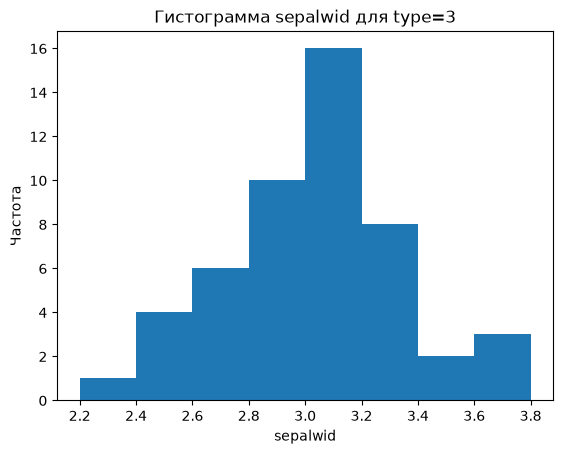

In [22]:
plt.hist(x, bins=8)
plt.title('Гистограмма sepalwid для type=3')
plt.xlabel('sepalwid')
plt.ylabel('Частота')
plt.show()

Гистограмма имеет выраженную одновершинную форму, 
близкую к симметричной. Она визуально согласуется с плотностью 
нормального распределения.

In [23]:
#аксцесс - то насколько острая гистограмма
#симметрия - то насколько тяжелые хвосты с одной из сторон гистограммы

In [24]:
#оценка плотности

### Эмпирическая функция распределения

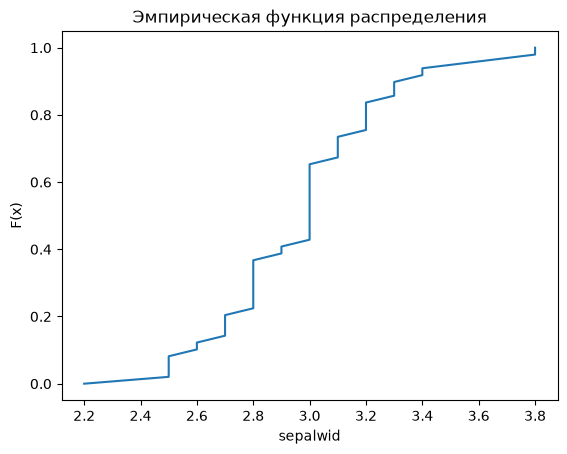

In [25]:
z = sorted(x)
t = np.linspace(0, 1, len(z))
plt.plot(z, t)
plt.title('Эмпирическая функция распределения')
plt.xlabel('sepalwid')
plt.ylabel('F(x)')
plt.show()

График визуально подтверждает гипотезу о нормальном распределении выборки.

### График квантиль-квантиль

Сравнивает эмпирические квантили выборки с теоретическими квантилями 
нормального распределения.

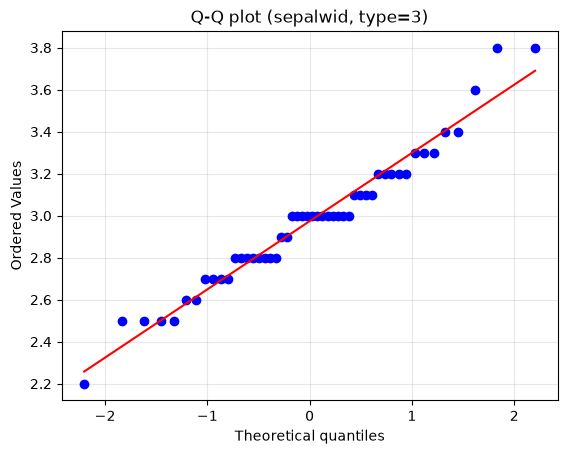

In [26]:
sts.probplot(x, dist="norm", plot=plt)
plt.title("Q-Q plot (sepalwid, type=3)")
plt.grid(alpha=0.3)
plt.show()

Данные нормальны — точки лежат на прямой линии. Небольшие отклонения на хвостах 
не критичны.

### Диаграмма размаха (boxplot)

Показывает медиану, квартили, усы (границы 1.5·IQR) и выбросы 
(точки за усами).

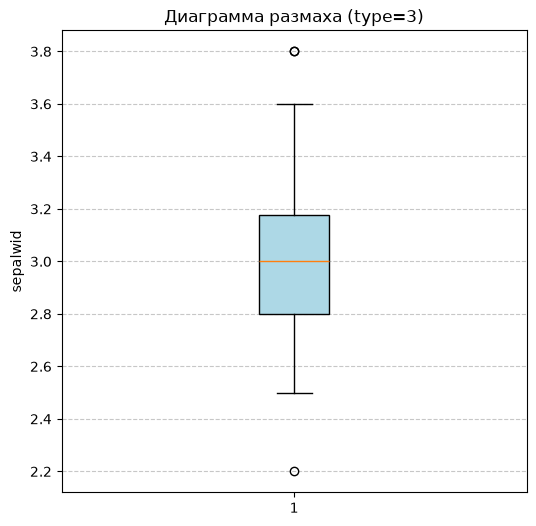

In [27]:
plt.figure(figsize=(6, 6))
plt.boxplot(x, notch=False, patch_artist=True,
            boxprops=dict(facecolor="lightblue"))
plt.ylabel("sepalwid")
plt.title("Диаграмма размаха (type=3)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Медиана делит ящик почти пополам, длина верхнего и нижнего усов 
примерно одинакова — распределение симметричное. Есть два выброса, это не критично

### Критерий Стьюдента

In [28]:
x1 = data[data['type'] == 1]['sepalwid'].values
x2 = data[data['type'] == 2]['sepalwid'].values
x3 = data[data['type'] == 3]['sepalwid'].values
t_stat, p_val = ttest_ind(x3, x1)
print(f"t-test 3 vs 1: t={t_stat:.4f}, p={p_val:.6f}")
t_stat, p_val = ttest_ind(x3, x2)
print(f"t-test 3 vs 2: t={t_stat:.4f}, p={p_val:.6f}")

t-test 3 vs 1: t=-6.4503, p=0.000000
t-test 3 vs 2: t=3.2058, p=0.001819


p < 0.05 - основание отвергнуть гипотезу о равенстве средних

In [29]:
F = x3.var(ddof=1) / x2.var(ddof=1)
df1, df2 = len(x3) - 1, len(x2) - 1
p = 2 * min(sts.f.cdf(F, df1, df2), 1 - sts.f.cdf(F, df1, df2))
print(f"F-test 3 vs 2: p={p:.6f}")

F-test 3 vs 2: p=0.848988


Если p >= 0.05 — нет оснований отвергнуть равенство дисперсий

### Критерий согласия Пирсона

In [30]:
freq, edges = np.histogram(x, bins=5)
print("Частоты:", freq)
print("Границы:", edges)

Частоты: [ 5 14 18 10  3]
Границы: [2.2  2.52 2.84 3.16 3.48 3.8 ]


In [31]:
edges_inf = edges.copy()
edges_inf[0] = -np.inf
edges_inf[-1] = np.inf

In [32]:
mu_hat = x.mean()
sigma_hat = x.std(ddof=1)

In [33]:
p = sts.norm.cdf(edges_inf[1:], mu_hat, sigma_hat) - \
    sts.norm.cdf(edges_inf[:-1], mu_hat, sigma_hat)
np_ = p * len(x)
print("Ожидаемые частоты:", np_)

Ожидаемые частоты: [ 3.98000474 12.96424296 18.95304688 11.18655706  2.91614836]


In [34]:
chi2_stat, chi2_p = sts.chisquare(freq, np_, ddof=2)
print(f"Chi-square: stat={chi2_stat:.4f}, p={chi2_p:.4f}")

Chi-square: stat=0.5203, p=0.7709


p > 0.05 нет оснований отвергнуть гипотезу что согласуется с нормальным.

## Вывод

Первичный статистический анализ ширины чашелистика ирисов типа 3 не даёт оснований для отклонения нулевой гипотезы H0 о нормальном законе распределения, так как аргументы в пользу этой модели преобладают. Коэффициент асимметрии (0.35) и эксцесс (0.52) близки к нулю, эмпирические квантили практически совпадают с теоретическими, а графики гистограммы, эмпирической функции распределения и Q-Q plot визуально подтверждают нормальность. В выборке наблюдается высокая симметрия и полное отсутствие аномальных выбросов по правилу трёх сигм, что дополнительно согласуется с гипотезой о нормальном распределении. Критерий согласия Пирсона (p = 0.77 > 0.05) также не отвергает H0.

При проверке однородности выявлено, что выборки sepalwid для типов 2 и 3 неоднородны по среднему значению (t-тест Стьюдента, p < 0.05): средняя ширина чашелистика у ирисов типа 3 значимо отличается от таковой у типа 2. Однако по дисперсии выборки можно считать однородными (F-тест Фишера, p = 0.85 > 0.05) — разброс значений внутри каждого типа примерно одинаков.
